# Prédiction du mois suivant : Normal ou Perturbé ?

- Le **score de fiabilité**  résume le **passé** d'une liaison : la part des trains prévus qui sont
  arrivés normalement.
- Ici, on cherche à **prévoir le mois suivant** : sera-t-il **Normal** ou **Perturbé** ?


Rappel: Une liaison est un triplet (gare de départ, gare d'arrivée, service).

## 1 Chargement des données 

### 1.1 Imports

In [1]:
import os
import sys

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from utils.nettoyage import nettoyer
from utils.journal import configurer_journal
from utils.graphiques import tracer_barres, tracer_matrices_confusion
from utils.prevision import (
    CLE_LIAISON,
    SEUIL_PERTURBATION,
    VARIABLES,
    ajouter_cible,
    calculer_variables,
    chercher_resultat,
    controler_comptages,
    creer_modele,
    decouper_train_test,
    detecter_mois_choc,
    entrainer_et_predire,
    entrainer_modele_final,
    exporter_predictions,
    importance_variables,
    mesurer,
    optimiser_foret,
    part_perturbee_selon_seuil,
    preparer_donnees,
    preparer_matrices,
    prevoir_mois_suivant,
    regle_mois_dernier,
    resultats_test,
    sensibilite_seuils,
    table_calibration,
)

chemin_logs = configurer_journal(dossier=os.path.join("..", "logs"))
print("Logs écrits dans :", chemin_logs)

dossier_donnees = os.path.join("..", "data")

Logs écrits dans : ../logs/sncf.log


### 1.2 Chargement

In [2]:
df_brut = pd.read_csv(os.path.join(dossier_donnees, "regularite-mensuelle-tgv-aqst.csv"), sep=";")
df, rapport = nettoyer(df_brut)

print(f"Fichier brut     : {df_brut.shape[0]} lignes, {df_brut.shape[1]} colonnes")
print(f"Après nettoyage  : {df.shape[0]} lignes, {df.shape[1]} colonnes")
pd.Series(rapport, name="valeur").to_frame()

Fichier brut     : 12544 lignes, 26 colonnes
Après nettoyage  : 12471 lignes, 25 colonnes


,valeur
lignes_initiales,12544
colonnes_supprimees,3
lignes_sans_circulation_supprimees,73
NaN : Nombre trains en retard > 30min,354
NaN : Retard moyen des trains en retard à l'arrivée,2
NaN : Retard moyen trains en retard > 15 (si liaison concurrencée par vol),8
NaN : Retard moyen de tous les trains au départ,170
NaN : Retard moyen de tous les trains à l'arrivée,121
lignes_finales,12471
cases_mises_a_nan,655


### 1.3 Choix des colonnes utiles

**Ce qu'on veut prédire.** La cible (section 2) est le taux de perturbation d'un mois : la part des trains prévus
qui sont annulés ou arrivent en retard. Les variables explicatives (section 3) sont ce même taux, découpé en
retards et annulations, mais calculé sur les mois **précédents**. Il suffit donc de trois comptages par mois :
les circulations prévues, les trains annulés et les trains en retard à l'arrivée.

**Ce qu'on ne garde pas, et pourquoi.** Les 26 colonnes du fichier se rangent en familles :

| Famille | Colonnes | Gardée ? | Raison |
|---|---|---|---|
| Identification | date, service, gares de départ et d'arrivée | **oui** | elles définissent une liaison et un mois |
| Identification | durée moyenne du trajet | non | elle ne change presque pas pour une liaison, et le modèle reconnaît déjà la liaison par son historique |
| Volumes | circulations prévues, trains annulés | **oui** | nécessaires aux taux |
| Retards à l'arrivée | nombre de trains en retard à l'arrivée | **oui** | nécessaire au taux de retard |
| Retards au départ | nombre et retards moyens au départ | non | le voyageur et l'assureur jugent un trajet à l'arrivée |
| Retards moyens | retards moyens (en minutes) au départ et à l'arrivée | non | notre cible compte des trains (annulés ou en retard), pas des minutes de retard ; ces colonnes contiennent aussi des valeurs négatives, difficiles à interpréter pour un retard) |
| Gravité | trains en retard de plus de 15, 30 et 60 min | non | même raison : la cible compte les trains en retard, quelle que soit la durée ; la colonne « > 30 min » contient des valeurs négatives et 354 lignes où « > 60 min » dépasse « > 30 min » |
| Causes | six pourcentages de causes | non | elles expliquent un retard une fois qu'il a eu lieu |
| Commentaires | trois colonnes de texte | non | presque toujours vides, et du texte libre inutilisable par le modèle |

Ne garder que ces colonnes a un autre avantage : les colonnes qui contiennent des valeurs négatives ou
incohérentes ne sont **jamais utilisées**, donc leurs erreurs ne peuvent pas fausser la prédiction. Il n'est pas
nécessaire de les corriger ici.

In [3]:
df_pred = preparer_donnees(df)

print(f"Dataset de travail : {len(df_pred)} lignes, {df_pred.groupby(CLE_LIAISON).ngroups} liaisons, "
      f"de {df_pred['Date'].min():%Y-%m} à {df_pred['Date'].max():%Y-%m}")

Dataset de travail : 12471 lignes, 146 liaisons, de 2018-01 à 2026-06


### 1.4 Contrôle de qualité des colonnes gardées

Un taux ne peut être calculé que si le nombre de circulations prévues est positif, et un comptage de trains ne peut pas être négatif.
On vérifie aussi que les nombres sont cohérents entre eux.

In [4]:
controler_comptages(df_pred).to_frame()

,lignes
Circulations prévues = 0,0
Comptage négatif,0
Comptage manquant,0
Annulés > prévues,0
Retards > trains réellement circulés,0


On remarque que tous les contrôles sont à 0 : les trois colonnes de comptage sont complètes et cohérentes. On peut
calculer les taux sans précaution supplémentaire.

## 2. Variable cible

### 2.1 Taux de perturbation du mois

On reprend l'indicateur du score de fiabilité, mais **mois par mois** :

$$\tau_{\text{mois}} = \frac{\text{annulés} + \text{retards à l'arrivée}}{\text{circulations prévues}}$$

C'est la part des trains prévus qui n'arrivent pas normalement. Le score du mois vaut donc
$100 \times (1 - \tau_{\text{mois}})$.

In [5]:
df_pred = ajouter_cible(df_pred)
df_pred["taux_perturbation"].describe(percentiles=[0.5, 0.6, 0.7, 0.75, 0.8, 0.9]).round(3)

count    12471.000
mean         0.179
std          0.108
min          0.000
50%          0.153
60%          0.174
70%          0.201
75%          0.219
80%          0.239
90%          0.310
max          1.000
Name: taux_perturbation, dtype: float64

### 2.2 Règle de classement

| Classe | Règle | Lecture avec le score |
|---|---|---|
| **Perturbé** | plus de 20 % des trains prévus sont annulés ou en retard | score du mois sous 80 / 100 |
| **Normal** | sinon | score du mois de 80 / 100 ou plus |

**Pourquoi 20 % ?** On l'a choisi
pour trois raisons.

1. **Il isole les mois nettement plus mauvais que d'habitude.** Le taux de perturbation mensuel a une médiane
   d'environ 15 %, et 20 % correspond à peu près à son 70e centile (tableau ci-dessus). Avec ce seuil, environ
   30 % des mois sont « Perturbés » : un mois perturbé fait partie du tiers le plus mauvais de l'historique, ce
   n'est pas un mois ordinaire.

2. **Il est cohérent avec le score de fiabilité.** Les liaisons du tiers « moins fiable » ont un score global
   inférieur à 81 sur toute la période. Un mois sous 80 est donc plus mauvais que le niveau habituel des liaisons
   les moins fiables : c'est un mois anormal, même pour une liaison fragile.
3. **Il laisse au modèle quelque chose d'utile à prévoir.** Un seuil plus bas rend la moitié des mois
   « Perturbés », et le mot ne veut plus rien dire. Un seuil plus haut retient surtout des mois de grève ou de
   Covid, qui sont imprévisibles, et le modèle y perd en précision. La section 6.5 vérifie ce point en refaisant
   le calcul avec plusieurs seuils.

Le tableau ci-dessous montre la part de mois perturbés selon le seuil choisi.

**Pourquoi ne pas séparer annulations et retards ?** Les annulations restent comptées dans le taux de
perturbation. Mais les annulations massives viennent surtout de chocs ponctuels (grèves, Covid), impossibles à
deviner à partir du passé d'une liaison. Les prévoir à part n'aurait pas de sens.

In [6]:
seuils_possibles = [0.15, 0.20, 0.25, 0.30]
display(part_perturbee_selon_seuil(df_pred, seuils_possibles).round(3).to_frame())

,part des mois perturbés
15%,0.518
20%,0.301
25%,0.177
30%,0.109


In [7]:
seuil_perturbation = SEUIL_PERTURBATION
df_pred = ajouter_cible(df_pred, seuil=seuil_perturbation)

print(f"Seuil retenu : {seuil_perturbation:.0%}")
print(f"Part des liaisons-mois perturbées : {df_pred['perturbe'].mean():.1%}")

Seuil retenu : 20%
Part des liaisons-mois perturbées : 30.1%


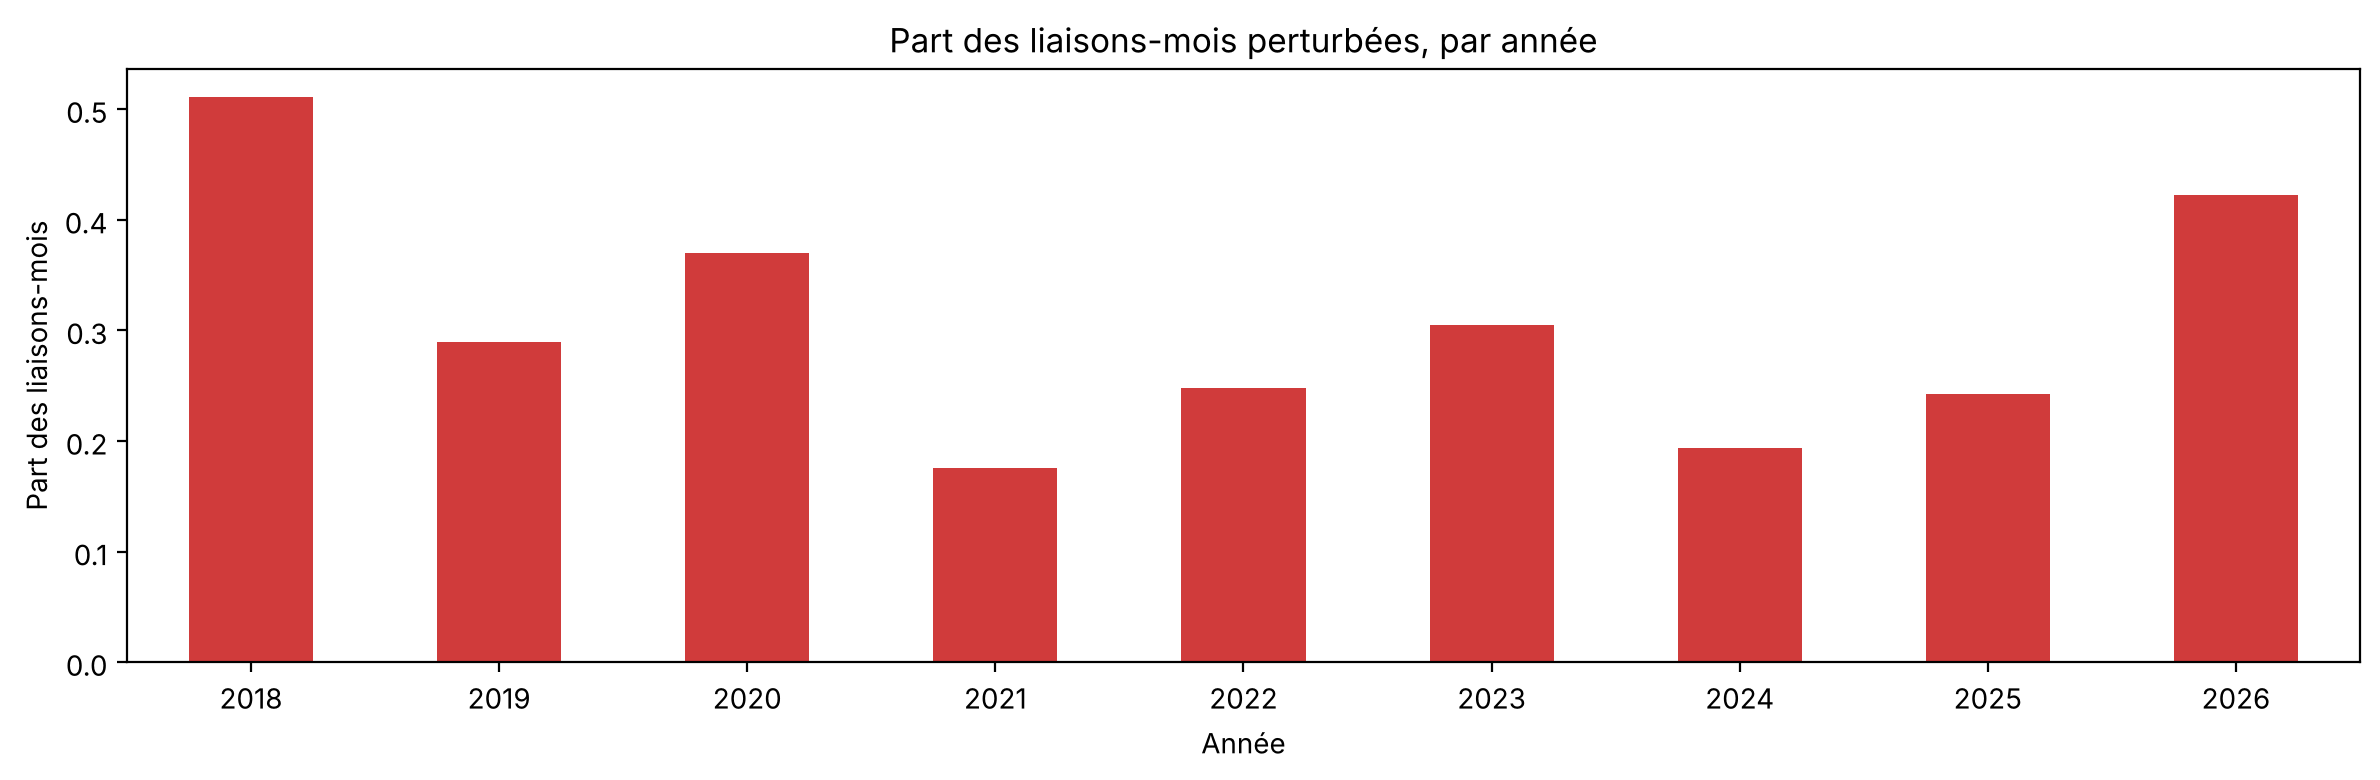

In [8]:
part_par_annee = df_pred.groupby(df_pred["Date"].dt.year)["perturbe"].mean()
fig = tracer_barres(part_par_annee, "Part des liaisons-mois perturbées, par année",
                    xlabel="Année", ylabel="Part des liaisons-mois", couleur="#d03b3b", taille=(12, 4))
plt.show()

## 3. Variables explicatives

Pour prévoir le mois $t$, on ne peut utiliser que ce qui est connu **à la fin du mois $t-1$**. Utiliser les retards
du mois $t$ lui-même reviendrait à donner la réponse au modèle.


| Variable | Signification |
|---|---|
| mois | mois de l'année visé (1 à 12) |
| international | 1 si la liaison est internationale |
| retard_mois_dernier | taux de retard du mois précédent |
| annulation_mois_dernier | taux d'annulation du mois précédent |
| retard_12_mois | taux de retard sur les 12 mois précédents (sommes, puis division) |
| annulation_12_mois | taux d'annulation sur les 12 mois précédents (sommes, puis division) |
| retard_an_dernier | taux de retard du même mois l'année précédente |
| annulation_an_dernier | taux d'annulation du même mois l'année précédente |

On garde les retards et les annulations séparés dans les variables : une liaison perturbée par des retards
réguliers ne se comporte pas comme une liaison touchée par une grève isolée.


In [9]:
table = calculer_variables(df_pred)

print(table.shape)
display(table[CLE_LIAISON + ["Date", "perturbe"] + VARIABLES].dropna().head())

(12778, 14)


,Gare de départ,Gare d'arrivée,Service,Date,perturbe,mois,international,retard_mois_dernier,annulation_mois_dernier,retard_12_mois,annulation_12_mois,retard_an_dernier,annulation_an_dernier
12,AIX EN PROVENCE TGV,PARIS LYON,National,2019-01-01,0.0,1,0,0.086387,0.007792,0.121538,0.042105,0.092040,0.000000
13,AIX EN PROVENCE TGV,PARIS LYON,National,2019-02-01,0.0,2,0,0.146530,0.010178,0.126295,0.043029,0.112360,0.000000
14,AIX EN PROVENCE TGV,PARIS LYON,National,2019-03-01,0.0,3,0,0.124646,0.022161,0.127261,0.044669,0.100515,0.020202
15,AIX EN PROVENCE TGV,PARIS LYON,National,2019-04-01,0.0,4,0,0.074742,0.010204,0.125055,0.043863,0.084967,0.260870
16,AIX EN PROVENCE TGV,PARIS LYON,National,2019-05-01,0.0,5,0,0.064865,0.008043,0.122880,0.021910,0.148571,0.146341


## 4. Jeux d'apprentissage et de test

### 4.1 Découpage dans le temps

On ne mélange pas les mois au hasard : le modèle verrait alors l'avenir pendant l'apprentissage. Il apprend sur
les mois jusqu'à **décembre 2024** et il est testé sur les mois **à partir de janvier 2025**, qu'il n'a jamais vus.

In [10]:
connues, train, test = decouper_train_test(table, date_coupure="2025-01-01")
print(f"Apprentissage : {len(train)} lignes | Test : {len(test)} lignes")

Apprentissage : 9395 lignes | Test : 2166 lignes


### 4.2 Retrait des mois de choc de l'apprentissage

Un mois de choc est un mois où tout le réseau TGV a été très perturbé en même temps, à cause d’un événement national (grève, confinement…), et pas à cause d’un problème propre à une liaison. Ces mois ne disent rien du comportement propre d'une
liaison : on les retire de l'apprentissage. On les **garde dans le test**, pour mesurer honnêtement ce que le
modèle sait faire.

In [11]:
mois_choc = detecter_mois_choc(df_pred)
print("Mois de choc :", [m.strftime("%Y-%m") for m in mois_choc])

connues, train, test = decouper_train_test(table, date_coupure="2025-01-01", mois_choc=mois_choc)
print(f"Apprentissage sans les mois de choc : {len(train)} lignes")

Mois de choc : ['2018-04', '2018-05', '2018-06', '2018-07', '2019-12', '2020-04', '2021-04', '2023-03']
Apprentissage sans les mois de choc : 8830 lignes


In [12]:
X_train, y_train, X_test, y_test, medianes = preparer_matrices(train, test)
print(f"Part de mois perturbés : apprentissage {y_train.mean():.1%} | test {y_test.mean():.1%}")

Part de mois perturbés : apprentissage 23.1% | test 30.0%


## 5. Modèles

On entraîne trois modèles classiques dans exactement les mêmes conditions (mêmes variables, même apprentissage) :
une régression logistique, un gradient boosting et une forêt aléatoire. Les mois perturbés étant minoritaires, tous
utilisent class_weight="balanced" pour ne pas les négliger. Chaque modèle donne une **probabilité** que le mois
soit perturbé ; on annonce « Perturbé » quand elle dépasse 50 %.

### 5.1 Régression logistique


In [13]:
modele_logistique, proba_logistique, y_predit_logistique = entrainer_et_predire(
    creer_modele("logistique"), X_train, y_train, X_test
)

### 5.2 Gradient boosting

In [14]:
modele_boosting, proba_boosting, y_predit_boosting = entrainer_et_predire(
    creer_modele("boosting"), X_train, y_train, X_test
)

### 5.3 Forêt aléatoire

In [15]:
modele, proba_test, y_predit = entrainer_et_predire(creer_modele("foret"), X_train, y_train, X_test)

In [16]:
regle = regle_mois_dernier(test, seuil_perturbation)

comparaison = pd.DataFrame({
    "Comme le mois dernier": mesurer(y_test, regle),
    "Régression logistique": mesurer(y_test, y_predit_logistique, proba_logistique),
    "Gradient boosting": mesurer(y_test, y_predit_boosting, proba_boosting),
    "Forêt aléatoire": mesurer(y_test, y_predit, proba_test),
}).T
display(comparaison.round(3))

,F1 macro,Rappel,Précision,AUC
Comme le mois dernier,0.699,0.534,0.608,NaN
Régression logistique,0.720,0.698,0.570,0.821
Gradient boosting,0.713,0.683,0.563,0.810
Forêt aléatoire,0.732,0.706,0.587,0.821


**Comme le mois dernier** : une règle de bon sens, sans apprentissage. On annonce « Perturbé » si le mois précédent
  dépassait 20 % de trains perturbés. Son taux de perturbation est reconstitué à partir des deux variables du mois
  précédent : taux d'annulation + (1 − taux d'annulation) × taux de retard. Elle sert de point de comparaison : un
  modèle qui ne fait pas mieux qu'elle n'a pas d'intérêt ;

On remarque que les trois modèles font à peu près aussi bien : leurs F1 et leurs AUC sont très proches. Le choix du
modèle compte peu ; l'essentiel de l'information est dans les variables, c'est-à-dire dans le passé récent de la
liaison. La forêt aléatoire obtient le meilleur F1 et la meilleure précision, avec une AUC égale à celle de la
régression logistique. On la retient pour la suite.

## 6. Évaluation


### 6.1 Matrice de confusion

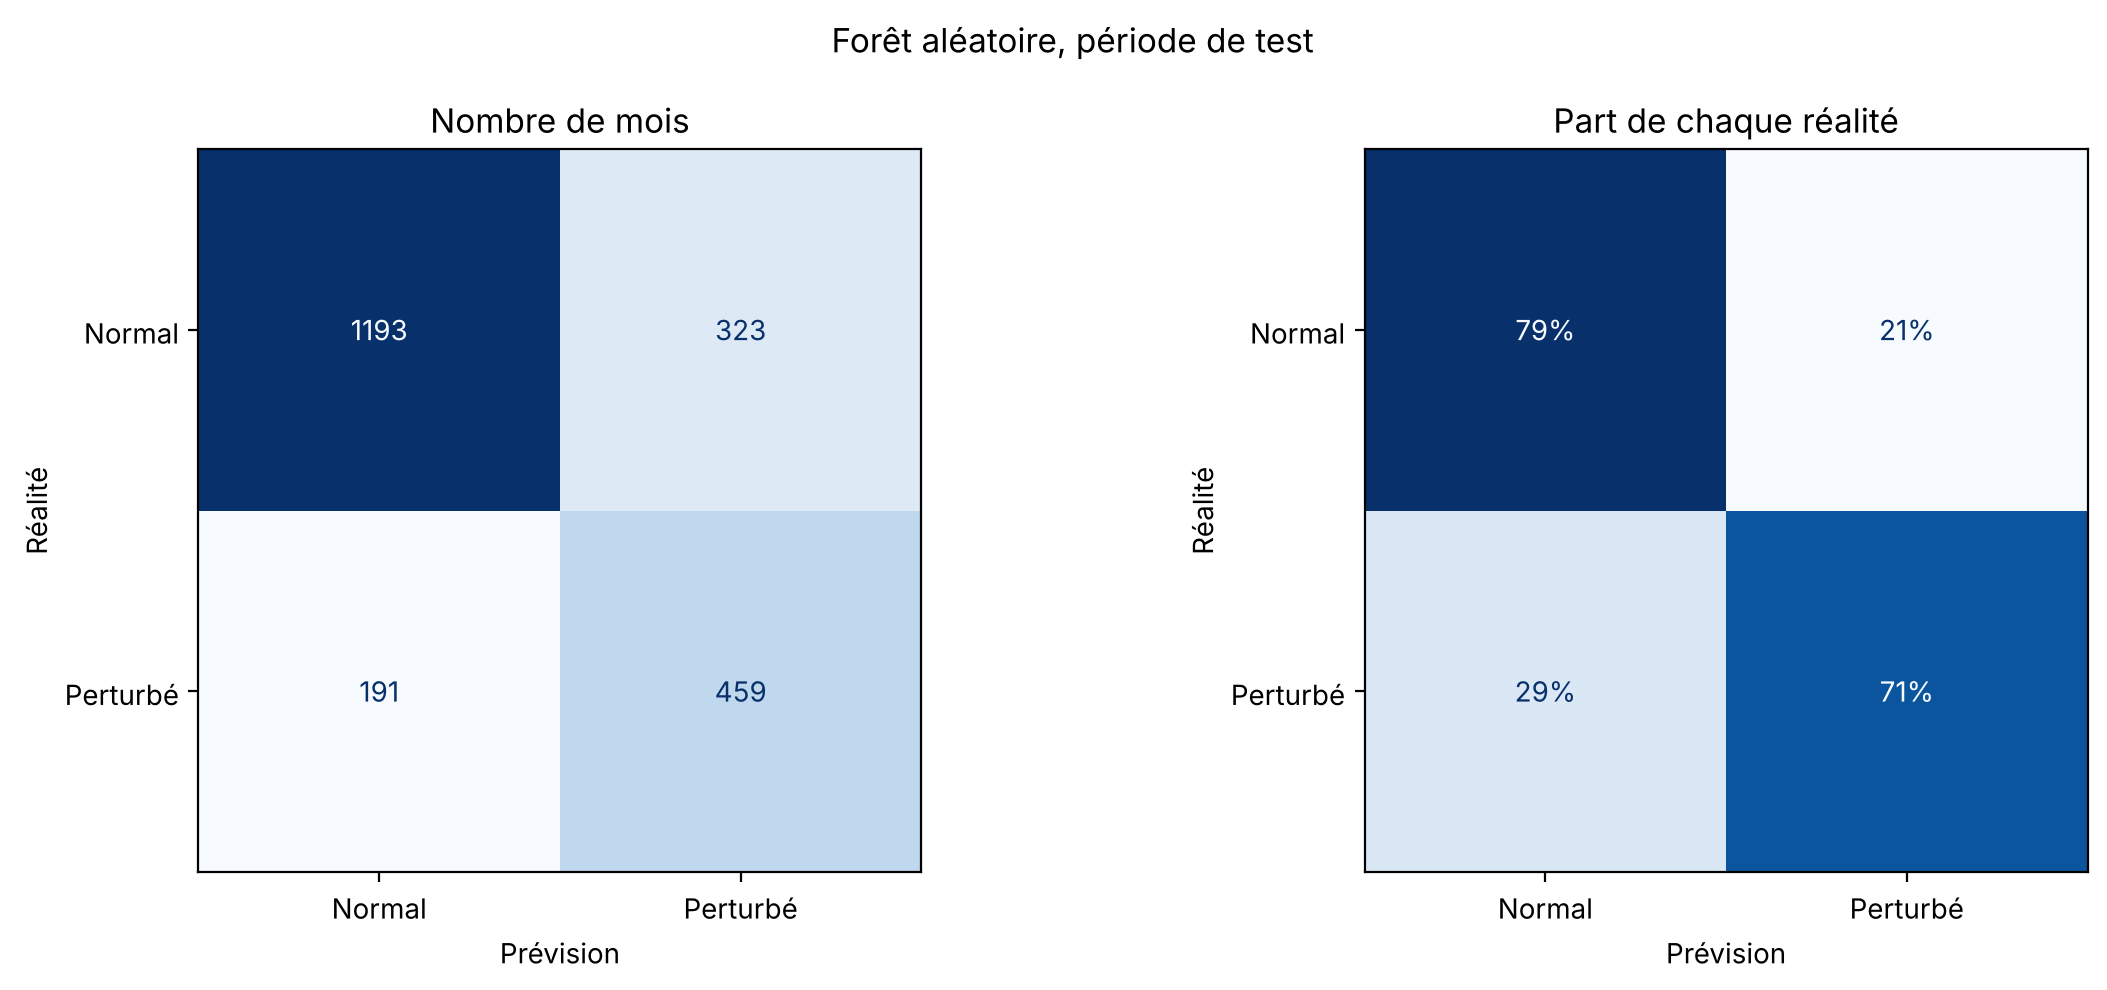

In [17]:
fig = tracer_matrices_confusion(y_test, y_predit, "Forêt aléatoire, période de test")
plt.show()

On remarque que le modèle repère environ 7 mois perturbés sur 10. En contrepartie, il annonce à tort environ 1 mois normal sur 5 comme perturbéce :ce sont les fausses alertes.
Pour un assureur, rater un mois à risque coûte en général plus cher qu'une fausse alerte, ce qui justifie ce compromis.

### 6.3 La probabilité a-t-elle un sens ?

Pour l'assureur, la probabilité compte plus que la réponse oui ou non : elle permet de moduler un prix. On range
les mois du test selon la probabilité donnée par le modèle, puis on regarde quelle part de chaque groupe a
réellement été perturbée. Si la probabilité a un sens, cette part doit monter avec elle.

,part réellement perturbée,nombre de mois
groupe,,
0-20 %,0.06,649
20-40 %,0.17,574
40-60 %,0.34,330
60-80 %,0.54,371
80-100 %,0.81,242


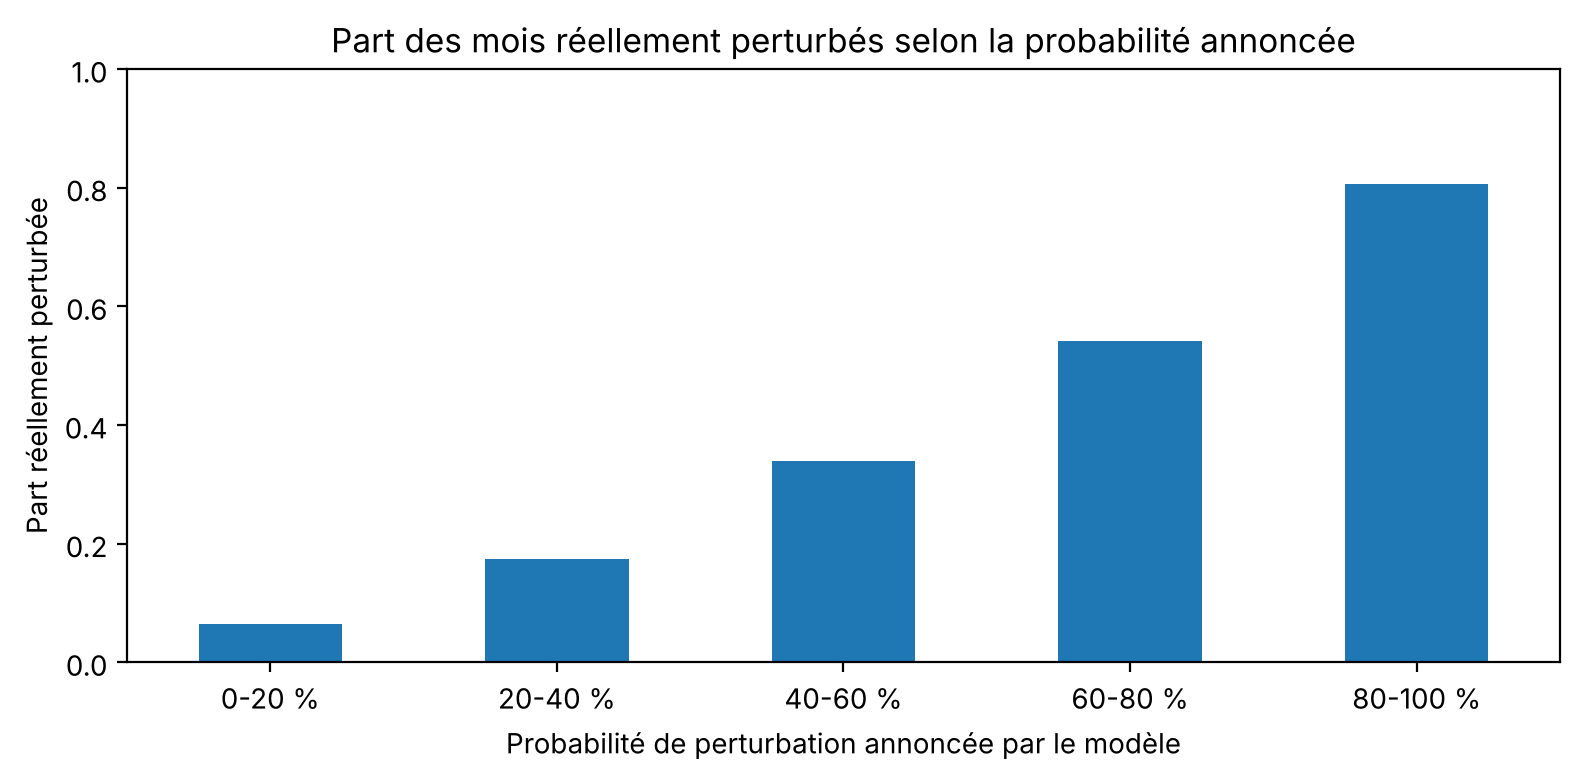

In [18]:
calibration = table_calibration(proba_test, y_test)
display(calibration.round(2))

fig = tracer_barres(calibration["part réellement perturbée"],
                    "Part des mois réellement perturbés selon la probabilité annoncée",
                    xlabel="Probabilité de perturbation annoncée par le modèle",
                    ylabel="Part réellement perturbée", ylim=(0, 1), taille=(8, 4))
plt.show()

On remarque que la part des mois réellement perturbés augmente avec la probabilité annoncée. Le modèle sait donc
ranger les mois du plus sûr au plus risqué, ce que résume l'AUC. Les probabilités ne sont pas exactes pour autant :
comme le modèle a été entraîné avec class_weight="balanced", il a tendance à les surestimer. Elles servent
surtout à **comparer** les liaisons et les mois entre eux.

### 6.4 Importance des variables

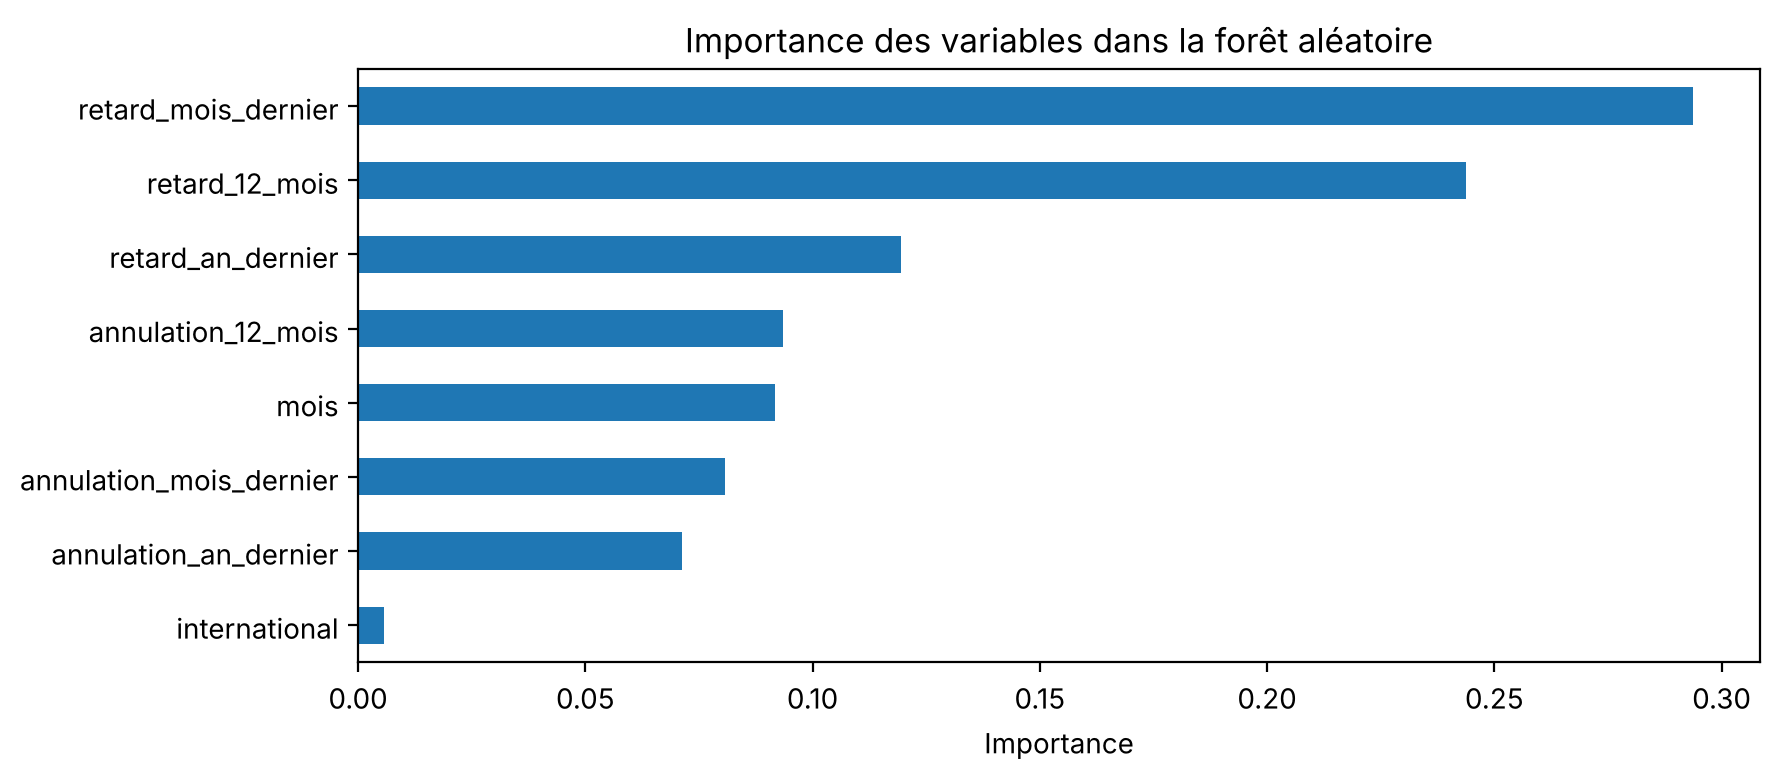

In [19]:
importance = importance_variables(modele)
fig = tracer_barres(importance, "Importance des variables dans la forêt aléatoire",
                    xlabel="Importance", horizontal=True, taille=(9, 4))
plt.show()

On remarque que les variables les plus utilisées sont les taux de retard récents (12 derniers mois et mois
précédent). Le mois de l'année et le même mois l'an dernier pèsent moins, en accord avec la faible saisonnalité.

### 6.5 Et avec un autre seuil ?

Le seuil de 20 % a été choisi en section 2.2. Pour vérifier que ce choix tient, on refait l'apprentissage et le test
avec quatre seuils (15 %, 20 %, 25 % et 30 %), en gardant exactement les mêmes variables et la même période de test.
Pour chaque seuil, on compare la forêt aléatoire à la règle « comme le mois dernier », et on regarde quelle part
des mois perturbés vient d'un mois de choc national.

In [20]:
sensibilite = sensibilite_seuils(df_pred, train, test, X_train, X_test, mois_choc, seuils_possibles)
display(sensibilite.round(2))

,mois perturbés (test),dont mois de choc (tout l'historique),rappel forêt,rappel règle,précision forêt,précision règle,F1 forêt,F1 règle
15%,0.53,0.14,0.71,0.69,0.79,0.73,0.74,0.70
20%,0.30,0.23,0.71,0.53,0.59,0.61,0.73,0.70
25%,0.16,0.35,0.65,0.44,0.43,0.53,0.70,0.70
30%,0.07,0.48,0.62,0.33,0.33,0.43,0.68,0.67


Le tableau présente, pour chaque seuil, la part de mois perturbés dans la période de test, la part des mois
perturbés qui tombent sur un mois de choc national, puis le rappel, la précision et le F1 de la forêt aléatoire et
de la règle « comme le mois dernier ».

On remarque que :
- **à 15 %**, la forêt aléatoire fait mieux que la règle sur toutes les mesures, mais plus de la moitié des mois
  sont « Perturbés ». Le seuil est au niveau de la médiane : un mois « perturbé » est alors un mois ordinaire, et
  la prévision n'apprend rien d'utile à un assureur ;
- **à 20 %**, la forêt repère nettement plus de mois perturbés que la règle (rappel de 71 % contre 53 %), avec une
  précision presque identique (59 % contre 61 %) ;
- **à 25 % et 30 %**, les mois perturbés deviennent rares et viennent de plus en plus des mois de choc (presque la
  moitié à 30 %). La forêt repère toujours plus de mois que la règle, mais sa précision passe nettement sous celle
  de la règle : à 30 %, quand elle annonce « Perturbé », elle se trompe deux fois sur trois. Le F1 de la forêt
  n'est alors plus meilleur que celui de la règle.

Par conséquent, 20 % est le seuil le plus exigeant pour lequel la forêt aléatoire repère beaucoup plus de mois
perturbés que le bon sens **sans perdre en précision**. Le choix reste une convention, mais il est cohérent avec
les résultats.

### 6.6 Les réglages de la forêt sont-ils les bons ?

Jusqu'ici, la forêt aléatoire utilise des réglages fixés à la main : des arbres sans limite de profondeur et au moins 5 mois par feuille. On vérifie que ce choix tient en essayant d'autres réglages :

| Réglage | Valeurs essayées | Rôle |
|---|---|---|
| `max_depth` | sans limite, 5, 10 | profondeur maximale de chaque arbre |
| `min_samples_leaf` | 1, 5, 20, 50 | nombre minimal de mois dans une feuille |

Des arbres moins profonds, ou des feuilles plus grandes, donnent des règles plus simples : le modèle colle moins aux particularités de l'apprentissage, mais il peut aussi passer à côté de cas utiles.

**Comment on compare les réglages.** On n'utilise **que l'apprentissage** (2018 à 2024) : la période de test doit rester intacte, sinon on choisirait les réglages qui réussissent le mieux sur 2025 et le score de test ne serait plus une vraie mesure. On fait une **validation croisée temporelle** : on découpe l'apprentissage en blocs de mois, puis, 5 fois de suite, on apprend sur les mois passés et on mesure le F1 sur les mois qui suivent. On n'utilise pas une validation croisée classique, qui mélangerait les mois et laisserait le modèle apprendre sur l'avenir, comme expliqué en section 4.1.

Pour chaque réglage, on garde la moyenne des 5 F1 et leur écart-type, qui indique à quel point le score varie d'une période à l'autre.


In [21]:
recherche, resultats_reglages = optimiser_foret(X_train, y_train, train["Date"])
display(resultats_reglages.round(3))

,max_depth,min_samples_leaf,F1 moyen,écart-type
0,5,50,0.704,0.026
1,5,1,0.703,0.021
2,5,20,0.703,0.019
3,5,5,0.702,0.017
4,10,50,0.699,0.029
5,None,50,0.699,0.028
6,10,1,0.696,0.029
7,None,1,0.695,0.023
8,None,5,0.693,0.020
9,10,5,0.692,0.018


In [22]:
modele_optimise, proba_optimise, y_predit_optimise = entrainer_et_predire(
    recherche.best_estimator_, X_train, y_train, X_test
)
comparaison_reglages = pd.DataFrame({
    "Réglages actuels": mesurer(y_test, y_predit, proba_test),
    "Meilleurs réglages en validation": mesurer(y_test, y_predit_optimise, proba_optimise),
}).T
display(comparaison_reglages.round(3))

,F1 macro,Rappel,Précision,AUC
Réglages actuels,0.732,0.706,0.587,0.821
Meilleurs réglages en validation,0.721,0.738,0.559,0.826


On remarque que les 12 réglages obtiennent presque le même F1 en validation, entre 0,690 et 0,704. Cet écart (0,014) est plus petit que la variation d'une période à l'autre (écart-type d'environ 0,02) : la validation croisée ne permet pas de dire qu'un réglage est vraiment meilleur qu'un autre. Les réglages actuels (sans limite de profondeur, 5 mois par feuille) obtiennent 0,693, dans le même ordre de grandeur.

Le réglage arrivé premier, des arbres de profondeur 5 avec au moins 50 mois par feuille, ne fait pas mieux sur la période de test : il repère un peu plus de mois perturbés (rappel 0,738 contre 0,706), mais au prix de davantage de fausses alertes (précision 0,559 contre 0,587), et son F1 baisse légèrement (0,721 contre 0,732).

**Conclusion.** Les réglages de la forêt ont très peu d'effet : ce qui limite le modèle, ce sont les informations disponibles (les 8 variables), pas la façon de régler les arbres. On garde donc les réglages actuels pour le modèle final. Ce choix vient de la validation croisée, qui ne départage pas les réglages ; le test confirme seulement qu'on ne perd rien à les garder.


## 7. Prévision du mois suivant

### 7.1 Modèle final

On réentraîne la forêt aléatoire sur **tous** les mois connus, pour profiter des données les plus récentes.

In [23]:
modele_final, medianes_finales = entrainer_modele_final(connues, mois_choc)

### 7.2 Prévision pour toutes les liaisons

Le mois à prévoir est celui qui suit la dernière donnée. On ne garde que les liaisons encore présentes le dernier
mois et qui ont assez d'historique.

In [24]:
predictions = prevoir_mois_suivant(modele_final, table, medianes_finales)

print(f"Mois prévu : {predictions['mois_prevu'].max():%Y-%m}, {len(predictions)} liaisons")
display(predictions["prevision"].value_counts())
display(predictions.sort_values("proba_perturbation", ascending=False).head(10))

Mois prévu : 2026-07, 121 liaisons


prevision
Perturbé    105
Normal       16
Name: count, dtype: int64

,Gare de départ,Gare d'arrivée,Service,mois_prevu,proba_perturbation,prevision
3115,LYON PART DIEU,MARNE LA VALLEE,National,2026-07-01,0.984,Perturbé
5532,PARIS EST,FRANCFORT,International,2026-07-01,0.981,Perturbé
6051,PARIS EST,STUTTGART,International,2026-07-01,0.977,Perturbé
3012,LYON PART DIEU,LILLE,National,2026-07-01,0.977,Perturbé
3222,LYON PART DIEU,MARSEILLE ST CHARLES,National,2026-07-01,0.976,Perturbé
1360,CHAMBERY CHALLES LES EAUX,PARIS LYON,National,2026-07-01,0.974,Perturbé
3638,MACON LOCHE,PARIS LYON,National,2026-07-01,0.969,Perturbé
2085,ITALIE,PARIS LYON,International,2026-07-01,0.964,Perturbé
5326,NICE VILLE,PARIS LYON,National,2026-07-01,0.964,Perturbé
12571,VALENCE ALIXAN TGV,PARIS LYON,National,2026-07-01,0.963,Perturbé


On remarque que la part de liaisons annoncées perturbées dépend beaucoup du **dernier mois connu**. Comme le risque
est surtout répétitif, un dernier mois très mauvais sur tout le réseau fait monter la probabilité de presque
toutes les liaisons. C'est le comportement attendu du modèle, mais il faut le garder en tête en lisant ces
prévisions.

### 7.3 Exemples


Pour rendre les résultats concrets, on regarde des cas réels de la période de test. Pour chaque liaison et chaque
mois, on affiche ce que le modèle savait (le mois précédent et les 12 derniers mois), la probabilité qu'il a
donnée, sa prédiction, celle de la règle « comme le mois dernier », et ce qui s'est réellement passé.

In [25]:
resultats = resultats_test(test, proba_test, y_predit, regle)

exemples = [
    ("PARIS MONTPARNASSE", "NANTES", "2025-06-01"),
    ("PARIS LYON", "NICE VILLE", "2026-06-01"),
    ("PARIS LYON", "NICE VILLE", "2025-07-01"),
    ("PARIS MONTPARNASSE", "NANTES", "2026-03-01"),
    ("PARIS EST", "STRASBOURG", "2026-01-01"),
]

tableau_exemples = pd.DataFrame([chercher_resultat(resultats, depart, arrivee, mois)
                                 for depart, arrivee, mois in exemples])
tableau_exemples = tableau_exemples[[
    "Gare de départ", "Gare d'arrivée", "Date",
    "retard_mois_dernier", "annulation_mois_dernier", "retard_12_mois",
    "proba_perturbation", "prediction_foret", "prediction_regle",
    "taux_perturbation", "realite", "resultat",
]]
tableau_exemples["Date"] = tableau_exemples["Date"].dt.strftime("%Y-%m")
display(tableau_exemples.round(3))

,Gare de départ,Gare d'arrivée,Date,retard_mois_dernier,annulation_mois_dernier,retard_12_mois,proba_perturbation,prediction_foret,prediction_regle,taux_perturbation,realite,resultat
9458,PARIS MONTPARNASSE,NANTES,2025-06,0.070,0.002,0.097,0.053,Normal,Normal,0.118,Normal,juste
8028,PARIS LYON,NICE VILLE,2026-06,0.249,0.005,0.196,0.875,Perturbé,Perturbé,0.356,Perturbé,juste
8017,PARIS LYON,NICE VILLE,2025-07,0.171,0.000,0.177,0.630,Perturbé,Normal,0.211,Perturbé,juste
9467,PARIS MONTPARNASSE,NANTES,2026-03,0.395,0.062,0.131,0.739,Perturbé,Perturbé,0.091,Normal,fausse alerte
5942,PARIS EST,STRASBOURG,2026-01,0.124,0.003,0.110,0.199,Normal,Normal,0.300,Perturbé,raté


Le tableau présente cinq cas réels. Les colonnes retard_mois_dernier, annulation_mois_dernier et
retard_12_mois sont ce que le modèle savait ; taux_perturbation et realite sont ce qui s'est passé.

On remarque que :
- **Paris Montparnasse - Nantes, juin 2025** : une liaison calme après un mois calme. Le modèle et la règle
  annoncent « Normal », avec raison ;
- **Paris Lyon - Nice, juin 2026** : une liaison habituellement fragile après un mauvais mois. Le modèle et la
  règle annoncent « Perturbé », avec raison ;
- **Paris Lyon - Nice, juillet 2025** : le mois précédent était sous le seuil, donc la règle annonce « Normal ».
  Mais la liaison a beaucoup de retards en temps normal (12 derniers mois), et le modèle annonce « Perturbé », avec
  raison. C'est ce type de cas qui lui permet de repérer plus de mois perturbés que la règle ;
- **Paris Montparnasse - Nantes, mars 2026** : fausse alerte. Février a été très mauvais, et le modèle a supposé que
  cela allait continuer. C'était un mauvais mois isolé ;
- **Paris Est - Strasbourg, janvier 2026** : raté. Rien dans le passé récent ne laissait prévoir la perturbation.
  Aucune méthode fondée sur l'historique ne peut prévoir ce type de cas.

### 7.4 Export

In [26]:
chemin_export = exporter_predictions(predictions, os.path.join("..", "resultats"))
print(chemin_export, predictions.shape)

../resultats/predictions_liaisons.csv (121, 6)
